In [4]:
import pandas as pd

sheets = pd.read_excel("online_retail_II.xlsx", sheet_name=None)

for name, df in sheets.items():
    print(name, df.shape)

Year 2009-2010 (525461, 8)
Year 2010-2011 (541910, 8)


In [5]:
df = pd.concat(sheets.values(), ignore_index=True)

print(df.shape)
df.head()

(1067371, 8)


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


In [6]:
df["Revenue"] = df["Quantity"] * df["Price"]

print(df.isna().sum())

Invoice             0
StockCode           0
Description      4382
Quantity            0
InvoiceDate         0
Price               0
Customer ID    243007
Country             0
Revenue             0
dtype: int64


In [7]:
df["Invoice"] = df["Invoice"].astype(str)

print("Cancelled invoices:", df["Invoice"].str.startswith("C").sum())
print("Negative quantity:", (df["Quantity"] < 0).sum())
print("Price zero or below:", (df["Price"] <= 0).sum())

Cancelled invoices: 19494
Negative quantity: 22950
Price zero or below: 6207


In [8]:
clean = df[
    (~df["Invoice"].str.startswith("C"))
    & (df["Quantity"] > 0)
    & (df["Price"] > 0)
].copy()

customers = clean.dropna(subset=["Customer ID"]).copy()

print("Rows before:", len(df))
print("Rows after cleaning:", len(clean))
print("Rows with Customer ID:", len(customers))
print("Total revenue:", round(clean["Revenue"].sum(), 2))

Rows before: 1067371
Rows after cleaning: 1041670
Rows with Customer ID: 805549
Total revenue: 20972594.57


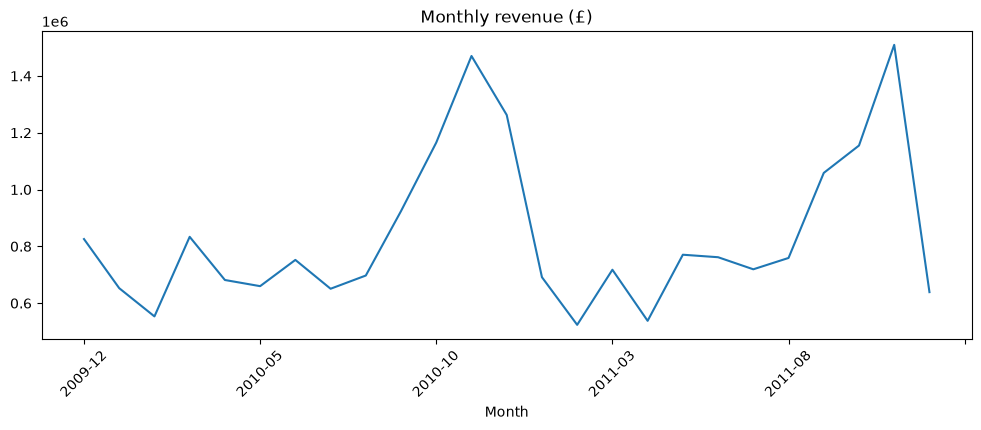

In [9]:
import matplotlib.pyplot as plt

clean["Month"] = clean["InvoiceDate"].dt.to_period("M").astype(str)
monthly = clean.groupby("Month")["Revenue"].sum()

monthly.plot(kind="line", figsize=(12, 4), title="Monthly revenue (£)")
plt.xticks(rotation=45)
plt.show()

In [10]:
monthly.sort_values(ascending=False).head(4)

Month
2011-11    1509496.330
2010-11    1470272.482
2010-12    1262598.790
2010-10    1165483.910
Name: Revenue, dtype: float64

In [11]:
orders_per_customer = customers.groupby("Customer ID")["Invoice"].nunique()

n_customers = len(orders_per_customer)
repeat = (orders_per_customer > 1).sum()

print("Customers:", n_customers)
print("Repeat customers:", repeat)
print("Repeat rate %:", round(repeat / n_customers * 100, 1))

Customers: 5878
Repeat customers: 4255
Repeat rate %: 72.4


In [12]:
rev_per_customer = customers.groupby("Customer ID")["Revenue"].sum().sort_values(ascending=False)

top_n = int(len(rev_per_customer) * 0.1)
share = rev_per_customer.head(top_n).sum() / rev_per_customer.sum() * 100

print("Top 10% =", top_n, "customers")
print("Their share of revenue %:", round(share, 1))

Top 10% = 587 customers
Their share of revenue %: 63.9


In [13]:
snapshot = customers["InvoiceDate"].max() + pd.Timedelta(days=1)

rfm = customers.groupby("Customer ID").agg(
    Recency=("InvoiceDate", lambda x: (snapshot - x.max()).days),
    Frequency=("Invoice", "nunique"),
    Monetary=("Revenue", "sum"),
)

rfm.head()

,Recency,Frequency,Monetary
Customer ID,,,
12346.0,326,12,77556.46
12347.0,2,8,5633.32
12348.0,75,5,2019.40
12349.0,19,4,4428.69
12350.0,310,1,334.40


In [14]:
rfm["R"] = pd.qcut(rfm["Recency"], 4, labels=[4, 3, 2, 1]).astype(int)
rfm["F"] = pd.qcut(rfm["Frequency"].rank(method="first"), 4, labels=[1, 2, 3, 4]).astype(int)
rfm["M"] = pd.qcut(rfm["Monetary"], 4, labels=[1, 2, 3, 4]).astype(int)

rfm["RFM"] = rfm["R"].astype(str) + rfm["F"].astype(str) + rfm["M"].astype(str)

rfm.head()

,Recency,Frequency,Monetary,R,F,M,RFM
Customer ID,,,,,,,
12346.0,326,12,77556.46,2,4,4,244
12347.0,2,8,5633.32,4,4,4,444
12348.0,75,5,2019.40,3,3,3,333
12349.0,19,4,4428.69,4,3,4,434
12350.0,310,1,334.40,2,1,1,211


In [15]:
def segment(row):
    if row["R"] >= 3 and row["F"] >= 3:
        return "Champions"
    elif row["R"] <= 2 and row["M"] >= 3:
        return "At risk (big spenders gone quiet)"
    elif row["R"] >= 3:
        return "Recent, low frequency"
    else:
        return "Lost / low value"

rfm["Segment"] = rfm.apply(segment, axis=1)

summary = rfm.groupby("Segment").agg(
    Customers=("R", "size"),
    Revenue=("Monetary", "sum"),
)
summary["Revenue %"] = (summary["Revenue"] / summary["Revenue"].sum() * 100).round(1)

summary.sort_values("Revenue", ascending=False)

,Customers,Revenue,Revenue %
Segment,,,
Champions,2059,1.361647e+07,76.7
At risk (big spenders gone quiet),919,2.642467e+06,14.9
"Recent, low frequency",894,7.699532e+05,4.3
Lost / low value,2006,7.145414e+05,4.0


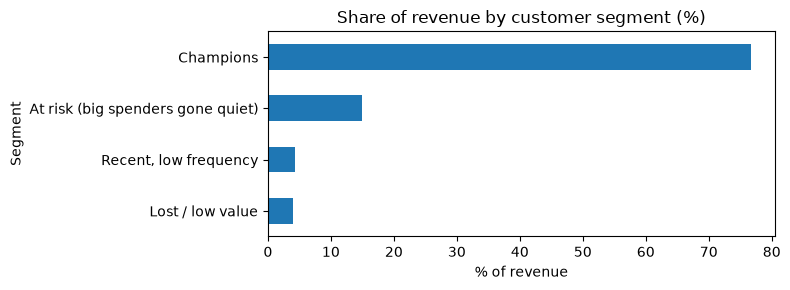

In [16]:
summary["Revenue %"].sort_values().plot(kind="barh", figsize=(8, 3), title="Share of revenue by customer segment (%)")
plt.xlabel("% of revenue")
plt.tight_layout()
plt.show()

In [17]:
import os
os.makedirs("images", exist_ok=True)

monthly.plot(kind="line", figsize=(12, 4), title="Monthly revenue (£), Dec 2009 to Dec 2011 (Dec 2011 is a partial month)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("images/monthly_revenue.png", dpi=150)
plt.close()

summary["Revenue %"].sort_values().plot(kind="barh", figsize=(8, 3), title="Share of revenue by customer segment (%)")
plt.xlabel("% of revenue")
plt.tight_layout()
plt.savefig("images/segments.png", dpi=150)
plt.close()

print(os.listdir("images"))

['monthly_revenue.png', 'segments.png']


In [18]:
with open(".gitignore", "w") as f:
    f.write("*.xlsx\n*.csv\n.ipynb_checkpoints/\n")

print(open(".gitignore").read())

*.xlsx
*.csv
.ipynb_checkpoints/

